# **Decision Trees**

## **1. Preprocessing**
   - 1.1 Importing packages and data: Importing and exploring the dataset, including feature descriptions, checking for missing values, and imbalance in the dataset.
   - 1.2 Data Exploration: Visualizing the distribution of features, checking imbalance, odd characters, correlation analysis, etc.
   - 1.3 Splitting Data

## **2. Basic Decision Tree Models**
   - 2.1 Training a Simple Decision Tree - Gini: Implementing decision tree classifiers using Gini impurity
   - 2.2 Visualising trees: Visualizing the trees to observe data splits and displaying feature importance.
   - 2.3 Training a Simple Decision Tree - Entropy: Implementing decision tree classifiers using Gini impurity
   - 2.4 Visualising trees: Visualizing the trees to observe data splits and displaying feature importance.
   - 2.5 Comparing performance


## **3. Transformations - Robustness of Decision Trees**
   - 3.1 Encoding: Comparing results with and without encoding
   - 3.2 Further Transformations: Demonstrating the robustness of decision trees to changes in data, such as scaling a feature and adding outliers.

## **4. Early Stopping**
   - 4.1 Choosing a parameter: Creating decision trees using early stopping criteria (like `max_depth`)
   - 4.2 Illustrating the differences in results.

## **5. Ensemble Methods and Their Comparison**
   - 5.1 Training a Random Forest.
   - 5.2 Choosing a parameter: Creating Random Forest using early stopping criteria (like `max_depth`)
   - 5.3 Comparing performance: Comparing Random Forest against the simple Decision Tree


Each code piece is structured to provide practical insights into different aspects of using decision trees and ensemble methods in machine learning. They cover various stages of a typical machine learning workflow, from data preparation to model evaluation and tuning.

# **1. Pre-processing**
### 1.1 Importing Packages and data

In [ ]:
# Importing Necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# Function to evaluate the model
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    print("ROC Score:", roc_auc_score(y_test, predictions))
    print("Accuracy Score", accuracy_score(y_test, predictions))


np.random.seed(0)

# Load the dataset
df = pd.read_csv("<path-to-dataset>/C2_W5_Datasets/processed.cleveland.csv")

target_col = "hd"
target = df[target_col]
data = df.drop(target_col,axis=1)
feature_names = list(data.columns)
df.rename({target_col:"target"},axis=1, inplace=True)

# Basic information about the dataset
print("Feature names:", feature_names)
print("Shape of X:", data.shape)
print("Sample of target values:", target[:10])  # Displaying the first 10 target values



Feature names: ['age', 'sex', 'cp', 'restbp', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Shape of X: (303, 13)
Sample of target values: 0    0
1    2
2    1
3    0
4    0
5    0
6    3
7    0
8    2
9    1
Name: hd, dtype: int64


### 1.2 Data Exploration

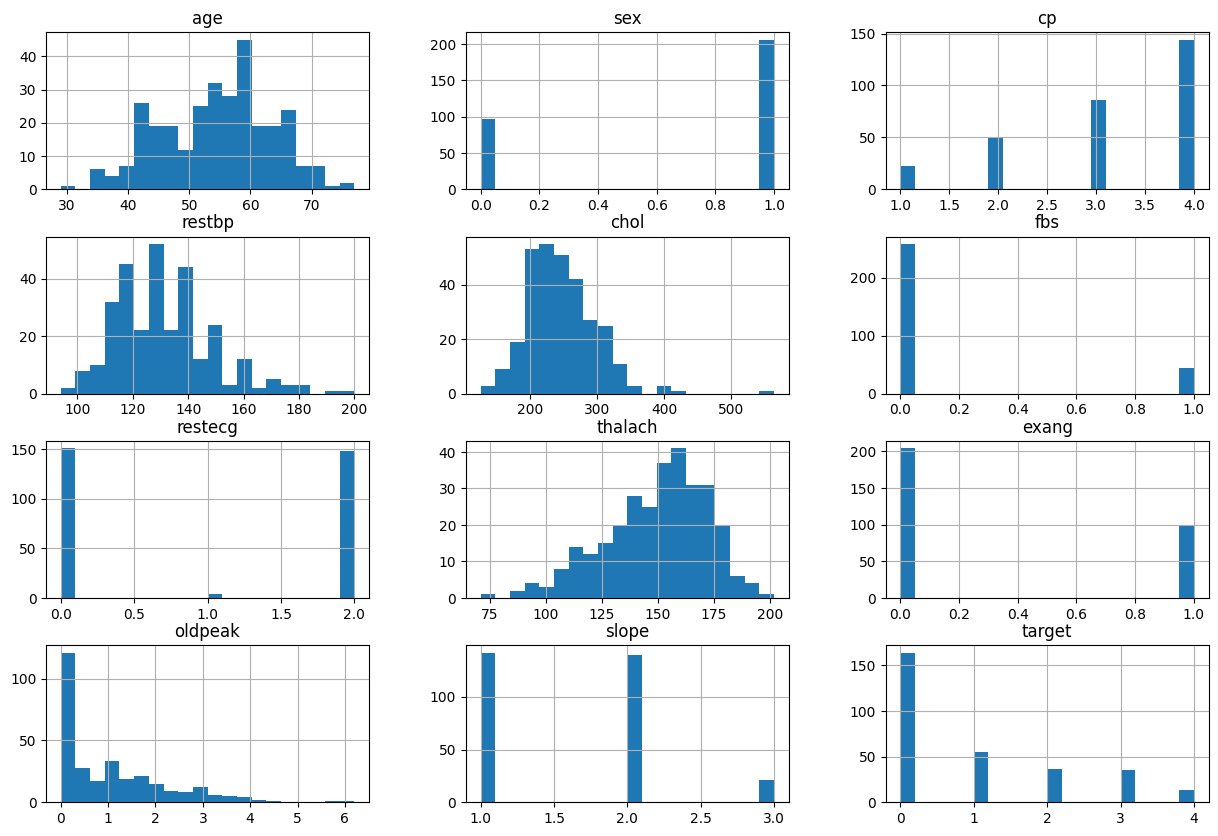

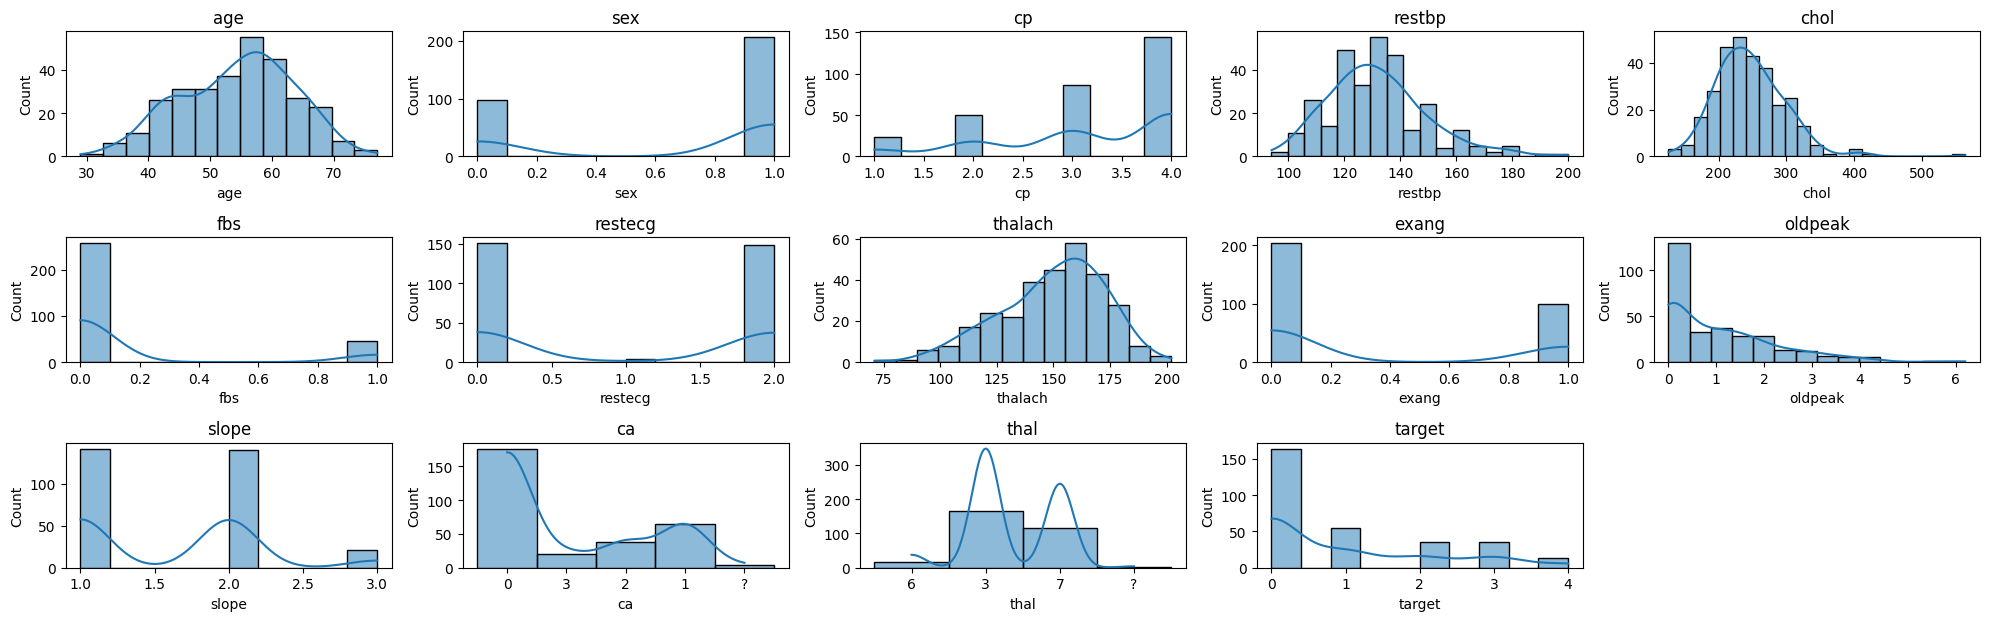

In [ ]:
###############
## Data Distributions
###############

# # Histograms
df.hist(bins=20, figsize=(15, 10))
plt.show()

# Visualizing distributions of features
plt.figure(figsize=(20, 10))
for i, col in enumerate(df.columns):
    plt.subplot(5, 5, i+1)
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.tight_layout()


In [ ]:
display(df.describe())

,age,sex,cp,restbp,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


In [ ]:
# Check for Nulls and data types
print(f"Nulls in data: {df.isnull().sum()} \n")

Nulls in data: age        0
sex        0
cp         0
restbp     0
chol       0
fbs        0
restecg    0
thalach    0
exang      0
oldpeak    0
slope      0
ca         0
thal       0
target     0
dtype: int64 



In [ ]:

print(f"Data types:\n {df.dtypes} \n")

Data types:
 age          int64
sex          int64
cp           int64
restbp       int64
chol         int64
fbs          int64
restecg      int64
thalach      int64
exang        int64
oldpeak    float64
slope        int64
ca          object
thal        object
target       int64
dtype: object 



In [ ]:
# Checking for imbalance in the dataset (assuming 'target' is the target variable)
print(df["target"].value_counts(normalize=True), end="\n\n")

target_not_zero = target > 0                         # get the index for each non-zero value in y
df.loc[target_not_zero,"target"] = 1               # set each non-zero value in y to 1
print(df["target"].value_counts(normalize=True))    # verify that y only contains 0 and 1.

target_names = ["No Heart Disease" if i==0 else "Heart Disease" for i in df["target"].unique()]     # Create a list of class names, assuming there are two classes


target
0    0.541254
1    0.181518
2    0.118812
3    0.115512
4    0.042904
Name: proportion, dtype: float64

target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


In [ ]:
# Why are 'ca' and 'thal' object, further inspect
print("Unique values for 'ca' and 'thal'",df[['ca','thal']].apply(np.unique), end="\n\n")


# Check the number of '?' instances
question_mark_obs = df.loc[(df['ca'] == '?')
                            |
                            (df['thal'] == '?')]

print("Number of observations with wild strings", len(question_mark_obs), end="\n\n")

# We can either remove these, fill them in with an imputer or leave them as missing values to let Ensemble models handle them.

# Remove  rows with ? from dataframe
df_no_wild_strings = df.loc[(df['ca'] != '?')
                       &
                       (df['thal'] != '?')]

# Replace rows with ? for missing values
df_as_missing = df.copy()
df_as_missing[['ca','thal']] = df[['ca','thal']].apply(lambda x: x.replace("?",np.nan).astype('float'))

print("Lenght dataset after removing wild strings", len(df_no_wild_strings), "\n")
print("Verifiying values for 'ca'", df_no_wild_strings['ca'].unique(), "\n")
print("Verifiying values for 'thal'", df_no_wild_strings['thal'].unique(), "\n")
print("New data date types", df_as_missing.dtypes)

Unique values for 'ca' and 'thal' ca      [0, 1, 2, 3, ?]
thal       [3, 6, 7, ?]
dtype: object

Number of observations with wild strings 6

Lenght dataset after removing wild strings 297 

Verifiying values for 'ca' ['0' '3' '2' '1'] 

Verifiying values for 'thal' ['6' '3' '7'] 

New data date types age          int64
sex          int64
cp           int64
restbp       int64
chol         int64
fbs          int64
restecg      int64
thalach      int64
exang        int64
oldpeak    float64
slope        int64
ca         float64
thal       float64
target       int64
dtype: object


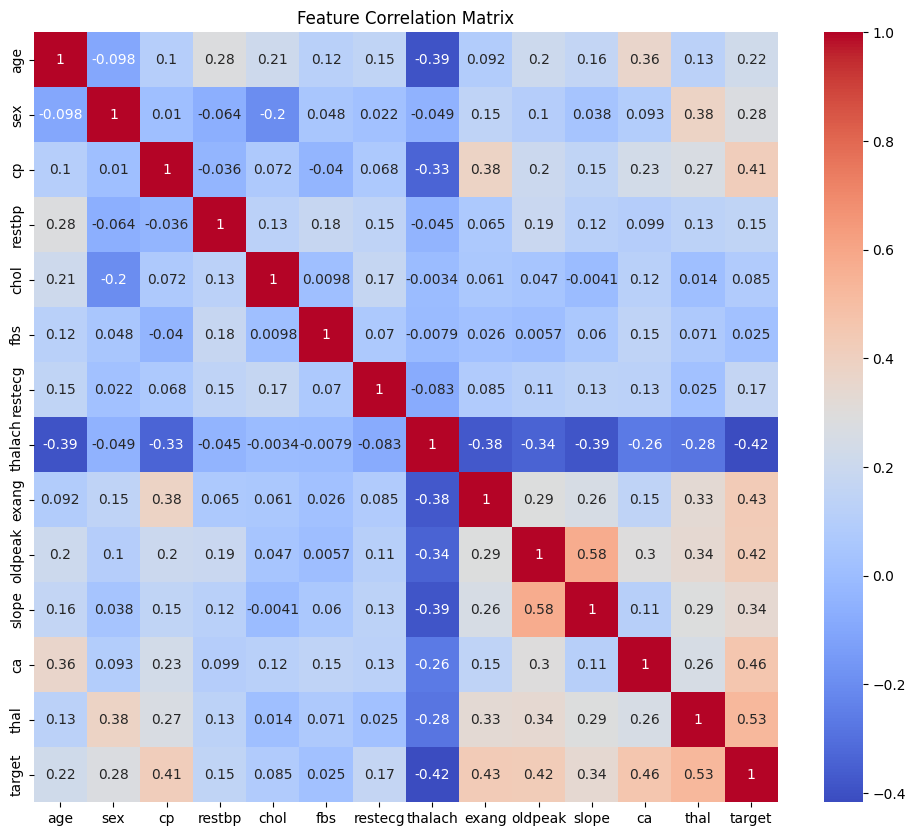

In [ ]:
# Correlation analysis
plt.figure(figsize=(12, 10))
sns.heatmap(df_as_missing.corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.show()

<Axes: >

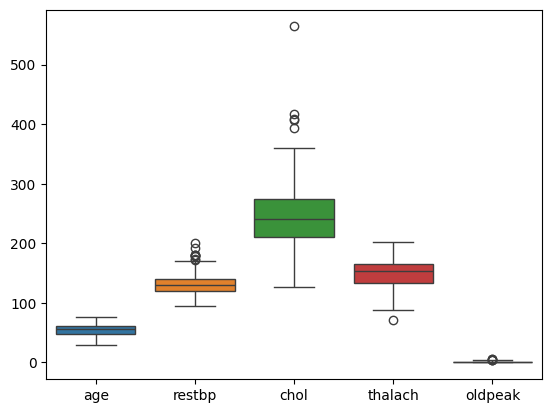

In [ ]:
# Check for outliers
sns.boxplot(data=df_as_missing[['age', 'restbp', 'chol', 'thalach', 'oldpeak']])


### 1.3 Split the data

In [ ]:
## Make a new copy of the columns used to make predictions
X = df_no_wild_strings.drop('target', axis=1).copy()
X.head()

y = df_no_wild_strings['target'].copy()
y.head()


## split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# **2. Basic Decision Tree models**

### 2.1 Fit a simple Decision Tree - Gini Impurity

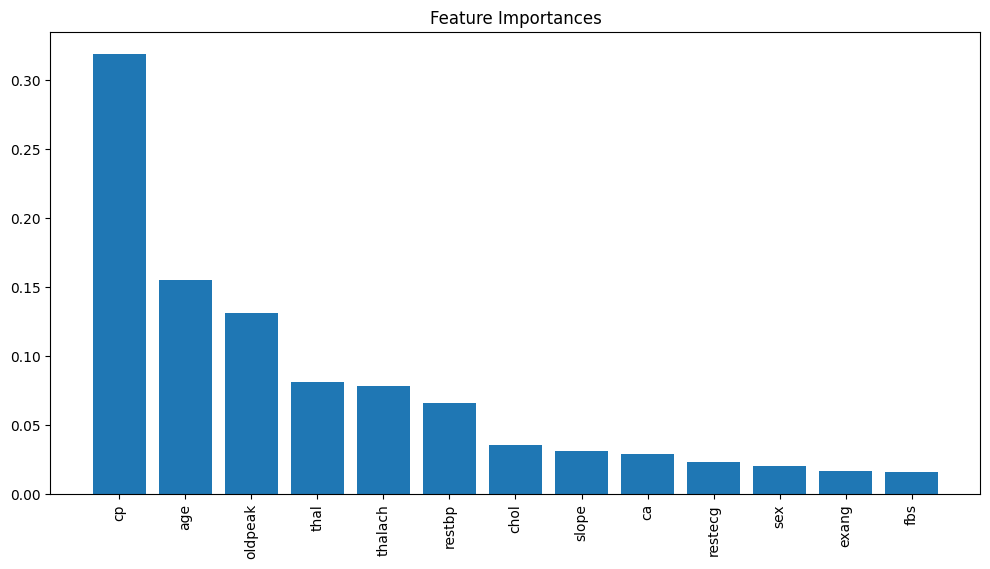

ROC Score: 0.7455357142857143
Accuracy Score 0.7444444444444445


In [ ]:

# Building Decision Tree Model
tree_classifier = DecisionTreeClassifier(criterion='gini', random_state=0)
tree_classifier.fit(X_train, y_train)

# Model Evaluation
y_pred_gini = tree_classifier.predict(X_test)

# Visualize feature importances
importances = tree_classifier.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.show()

# Evaluate the basic tree classifier
evaluate_model(tree_classifier, X_test, y_test)

### 2.2 Visualise Decision Trees

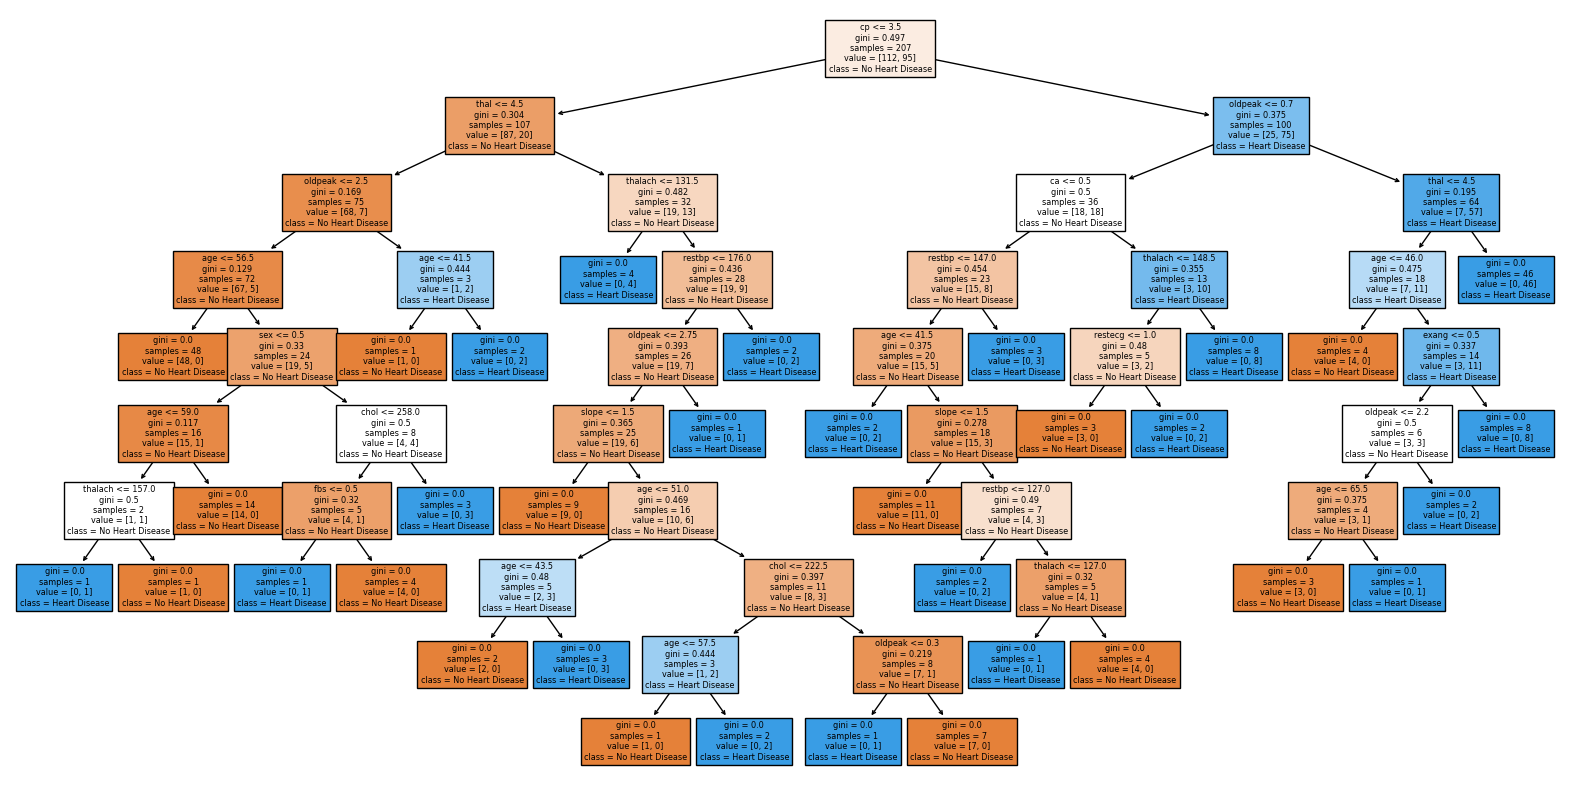

In [ ]:
# Decision Tree Visualization
plt.figure(figsize=(20,10))
plot_tree(tree_classifier, feature_names=list(X_train.columns), class_names=target_names, filled=True)
plt.show()

### 2.3 How is importance calculated



#### Feature Importance Plot
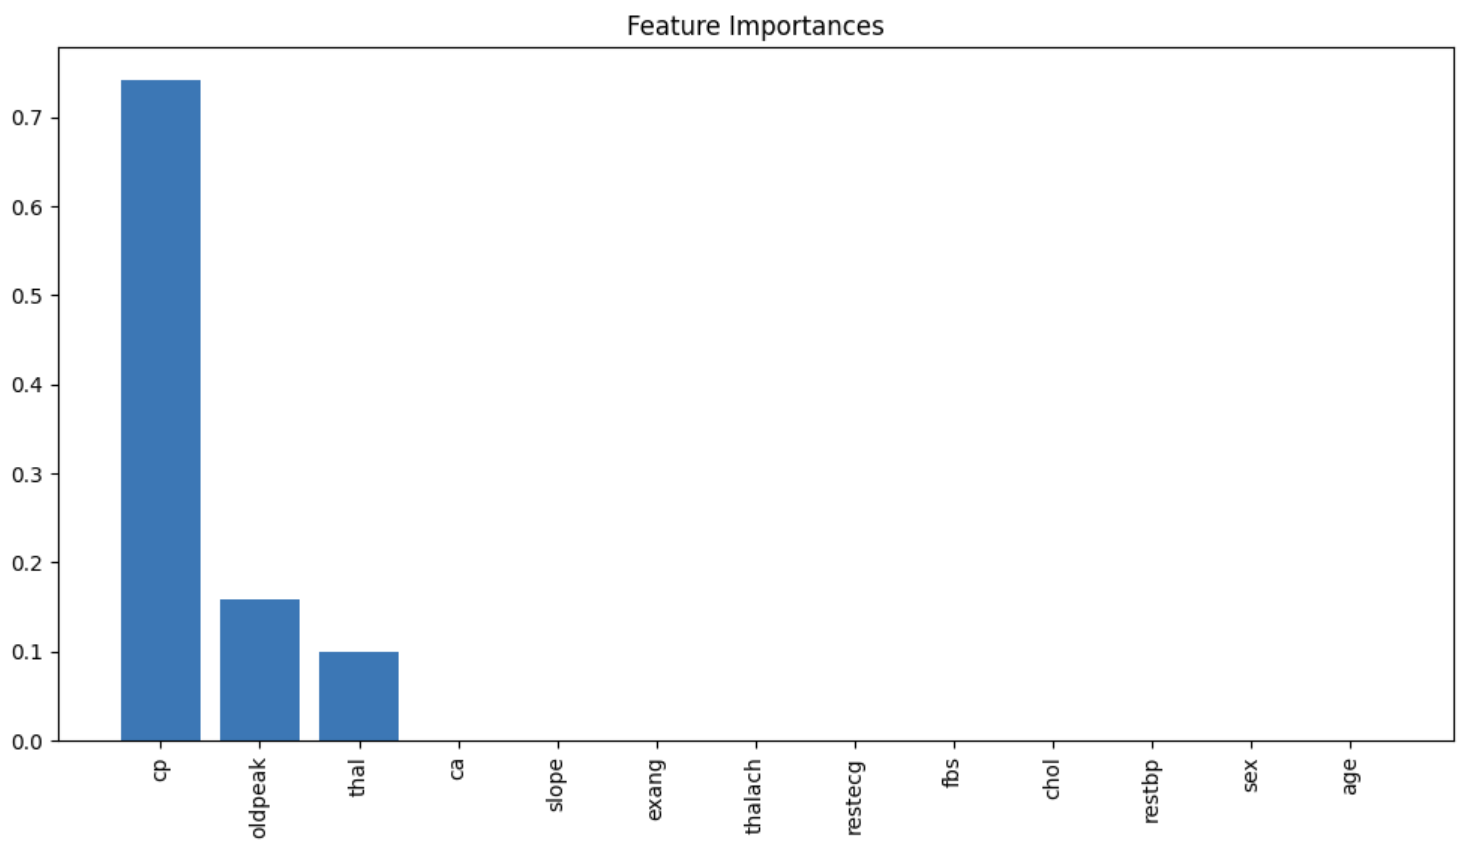

#### Decision Tree plot

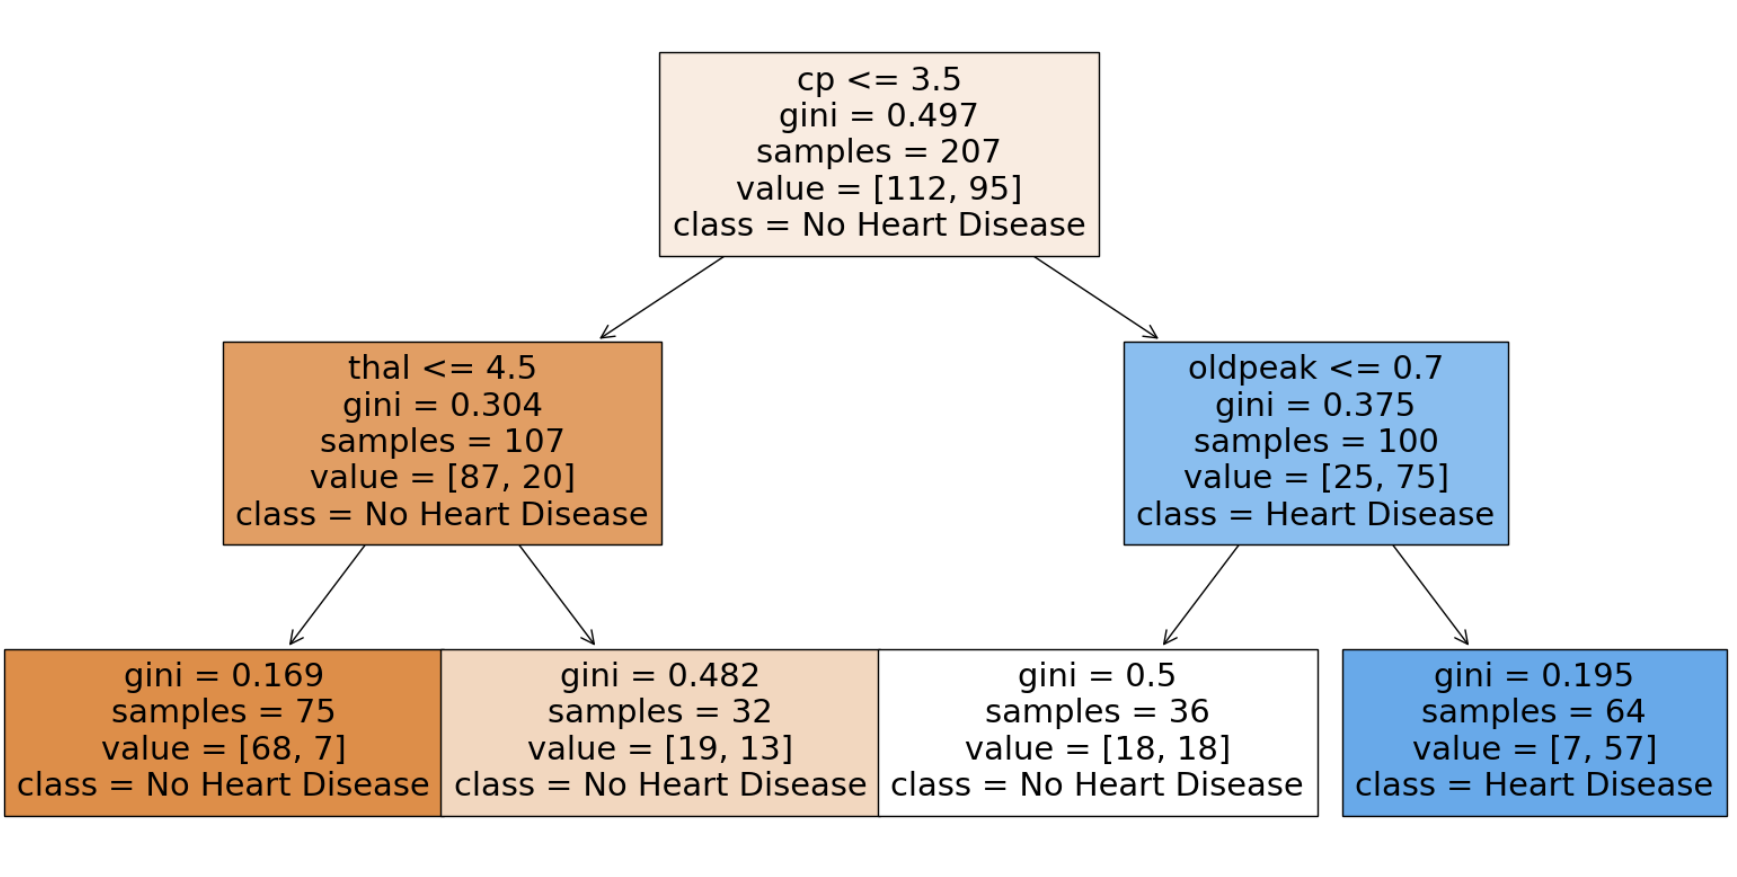



In [ ]:
# Define the Gini impurity and the number of samples for each node
nodes = {
    'root': {'gini': 0.497, 'samples': 207},
    'root_left': {'gini': 0.304, 'samples': 107},
    'root_right': {'gini': 0.375, 'samples': 100},
    'left_left': {'gini': 0.169, 'samples': 75},
    'left_right': {'gini': 0.482, 'samples': 32},
    'right_left': {'gini': 0.5, 'samples': 36},
    'right_right': {'gini': 0.195, 'samples': 64}
}

cp_gini_gain = (0.497 * 1)  - (0.304 * 107/207  +   0.375 * 100/207)

# Function to calculate the weighted Gini for a node
def weighted_gini(node):
    return nodes[node]['gini'] * (nodes[node]['samples'] / nodes['root']['samples'])


# Calculate the Gini gain for each feature
gini_gain = {
    'cp': weighted_gini('root') - (weighted_gini('root_left') + weighted_gini('root_right')),
    #cd_gini_gain =  (0.497 * 1)  - (0.304 * (107/207) + 0.375 * (100/207))

    'thal': weighted_gini('root_left') - (weighted_gini('left_left') + weighted_gini('left_right')),
    'oldpeak': weighted_gini('root_right') - (weighted_gini('right_left') + weighted_gini('right_right'))
}

print(gini_gain)
print(cp_gini_gain)

# Normalize the Gini gains to sum to 1 for feature importance
total_gain = sum(gini_gain.values())
print(total_gain)

feature_importances = {k: v / total_gain for k, v in gini_gain.items()}
print(gini_gain["cp"]/total_gain)

# Output the feature importances
print("\nFeature importances:")
for feature, importance in feature_importances.items():
    print(f"{feature}: {importance:.4f}")


{'cp': 0.15870048309178741, 'thal': 0.0213961352657005, 'oldpeak': 0.03391304347826088}
0.15870048309178741
0.2140096618357488
0.7415575620767493

Feature importances:
cp: 0.7416
thal: 0.1000
oldpeak: 0.1585


### 2.4 Fit a simple Decision Tree - Entropy

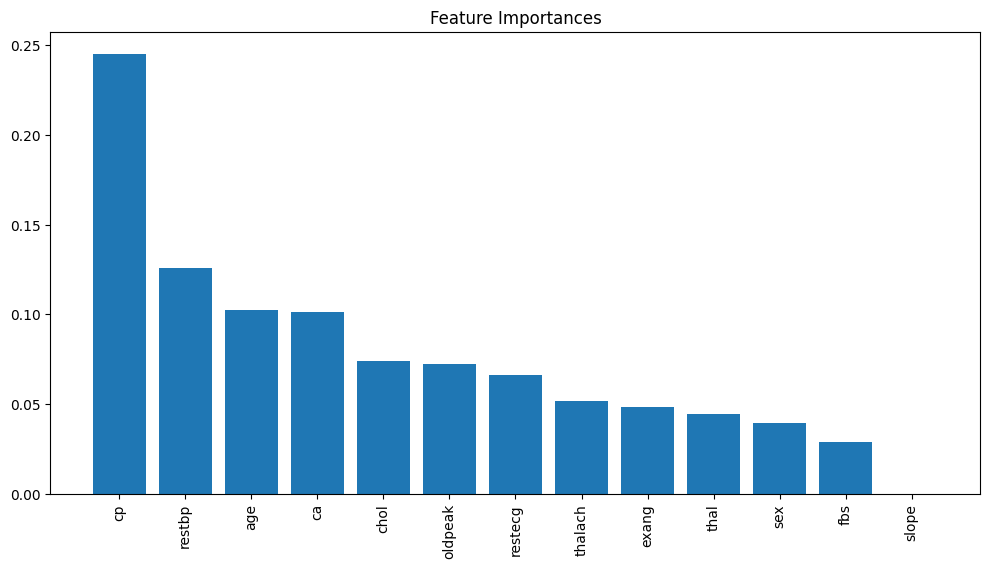

ROC Score: 0.730654761904762
Accuracy Score 0.7333333333333333


In [ ]:

# Decision Tree using Entropy
entropy_tree = DecisionTreeClassifier(criterion='entropy', random_state=0)
entropy_tree.fit(X_train, y_train)
entropy_tree_pred = entropy_tree.predict(X_test)



# Visualize feature importances
importances = entropy_tree.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.show()

# Evaluate the basic tree classifier
evaluate_model(entropy_tree, X_test, y_test)


### 2.5 Visualise Decision Tree - Entropy

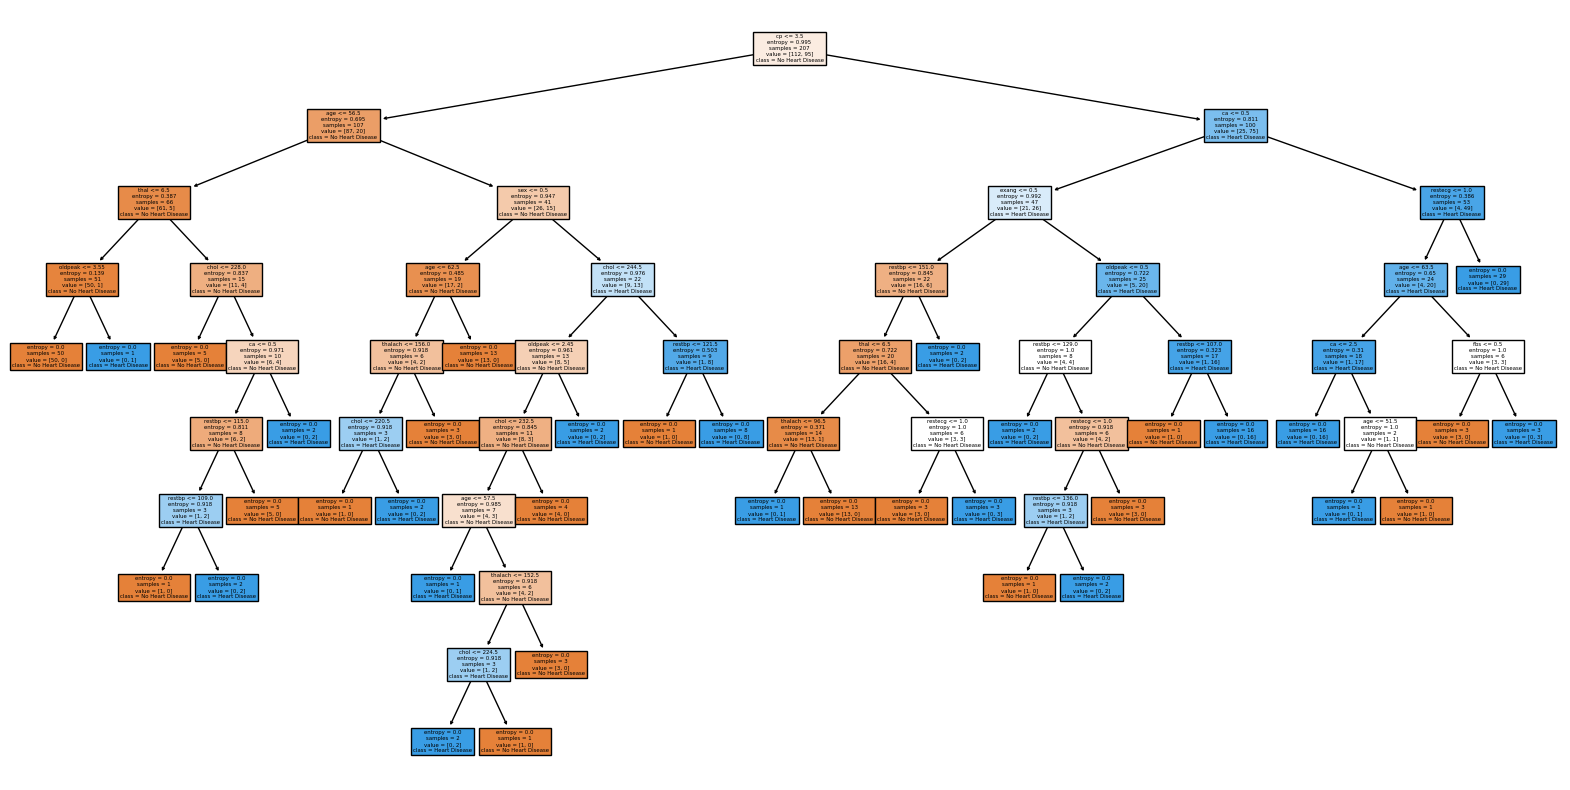

In [ ]:
# Decision Tree Visualization
plt.figure(figsize=(20,10))
plot_tree(entropy_tree, feature_names=list(X_train.columns), class_names=target_names, filled=True)
plt.show()

### 2.6 Compare Results

In [ ]:
gini_accuracy = accuracy_score(y_test, y_pred_gini)
entropy_accuracy = accuracy_score(y_test, entropy_tree_pred)

print(f"Accuracy using Gini Impurity: {gini_accuracy:.2f}")
print(f"Accuracy using Entropy: {entropy_accuracy:.2f}")


Accuracy using Gini Impurity: 0.74
Accuracy using Entropy: 0.73


# **3. Transformations - Robustness of Decision Trees**

### 3.1 Encoding: With vs Without

In [ ]:

# Look for potential categorical variables
n_unique_values = X.apply(lambda x: x.nunique())
print("Number of unique values for all features:\n", n_unique_values, end="\n\n")

# I will estimate 10 as my accepted threshold, but you can set it to whatever makes sense for your dataset
categories = n_unique_values[n_unique_values<10]
print("Features with less than 10 categories:\n",categories, end='\n')
categorical_features = list(categories.index)
numerical_features = [c for c in X_train.columns if  c not in categorical_features]
print("\nNumerical Features:\n ", numerical_features)

### One Hot Encoding - Train
enc = OneHotEncoder(sparse_output=False,handle_unknown="ignore")
X_train_encoded = X_train.copy()
X_train_encoded.drop(categorical_features,axis=1,inplace=True)
X_train_encoded_features = enc.fit_transform(X_train[categorical_features])
encoded_feature_names = enc.get_feature_names_out(categorical_features)

# Create the OHE dataset
X_train_encoded.loc[:,encoded_feature_names] = X_train_encoded_features
X_train_encoded.head()


### One Hot Encoding - Test
X_test_encoded = X_test.copy()
X_test_encoded.drop(categorical_features,axis=1,inplace=True)
X_test_encoded_features = enc.transform(X_test[categorical_features])

# Create the OHE dataset
X_test_encoded.loc[:,encoded_feature_names] = X_test_encoded_features
X_test_encoded.head()

# Make new column list
encoded_feature_names = list(X_train_encoded.columns)

Number of unique values for all features:
 age         41
sex          2
cp           4
restbp      50
chol       152
fbs          2
restecg      3
thalach     91
exang        2
oldpeak     40
slope        3
ca           4
thal         3
dtype: int64

Features with less than 10 categories:
 sex        2
cp         4
fbs        2
restecg    3
exang      2
slope      3
ca         4
thal       3
dtype: int64

Numerical Features:
  ['age', 'restbp', 'chol', 'thalach', 'oldpeak']


In [ ]:

# Building Decision Tree Model
tree_classifier_encoded = DecisionTreeClassifier(criterion='gini', random_state=0)
tree_classifier_encoded.fit(X_train_encoded, y_train)

# Model Evaluation
y_pred_encoded = tree_classifier_encoded.predict(X_test_encoded)

gini_accuracy = accuracy_score(y_test, y_pred_gini)
gini_accuracy_encoded = accuracy_score(y_test, y_pred_encoded)

print(f"Accuracy Without Encoding: {gini_accuracy:.2f}")
print(f"Accuracy With Encoding : {gini_accuracy_encoded:.2f}")



Accuracy Without Encoding: 0.74
Accuracy With Encoding : 0.79


### 3.2 Further Transformations: Scaling, Outliers, OHE, Imputer

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import random

X_train_modified = X_train_encoded.copy()
X_test_modified = X_test_encoded.copy()

# Adding outliers
outliers = 5
outlier_indices = sorted(random.sample(list(X_train_modified.index), outliers))
random_chol = [int(i) for i in np.random.uniform(550, 700, outliers)]
X_train_modified.loc[outlier_indices, 'chol'] = random_chol

scaler = StandardScaler()
X_train_modified[numerical_features] = scaler.fit_transform(X_train_modified[numerical_features])
X_test_modified[numerical_features] = scaler.transform(X_test_modified[numerical_features])



# Creating a decision tree with the modified data
modified_tree = DecisionTreeClassifier(random_state=0)
modified_tree.fit(X_train_modified, y_train)

y_pred_transformations =  modified_tree.predict(X_test_modified)

gini_accuracy_encoded = accuracy_score(y_test, y_pred_encoded)
gini_accuracy_transformations = accuracy_score(y_test, y_pred_transformations)

print(f"Accuracy Without Further Transformations: {gini_accuracy_encoded:.2f}")
print(f"Accuracy With Further Transformations: {gini_accuracy_transformations:.2f}")


Accuracy Without Further Transformations: 0.79
Accuracy With Further Transformations: 0.79


# **4. Early Stopping**
### 4.1 Choosing a parameter: Creating decision trees using early stopping criteria

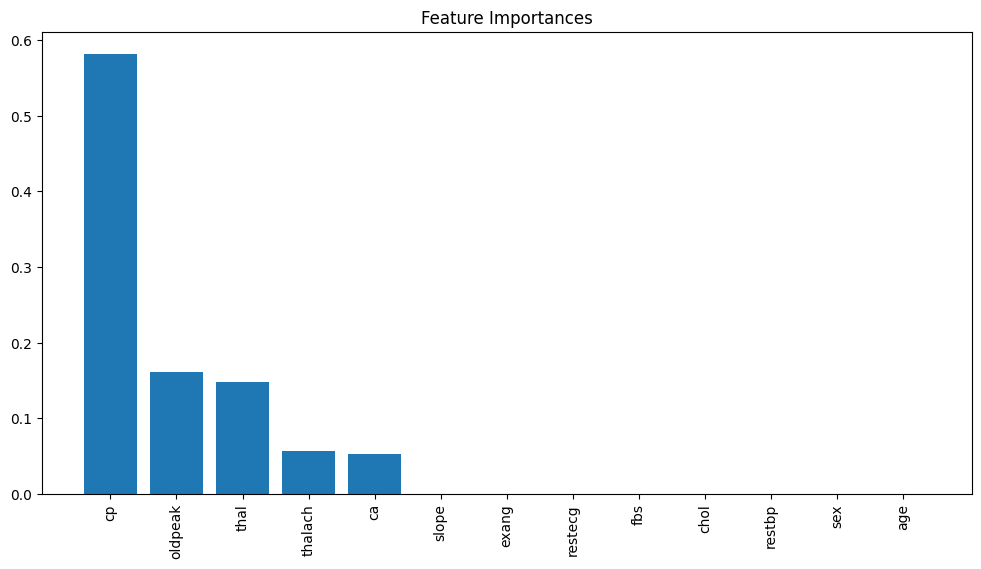

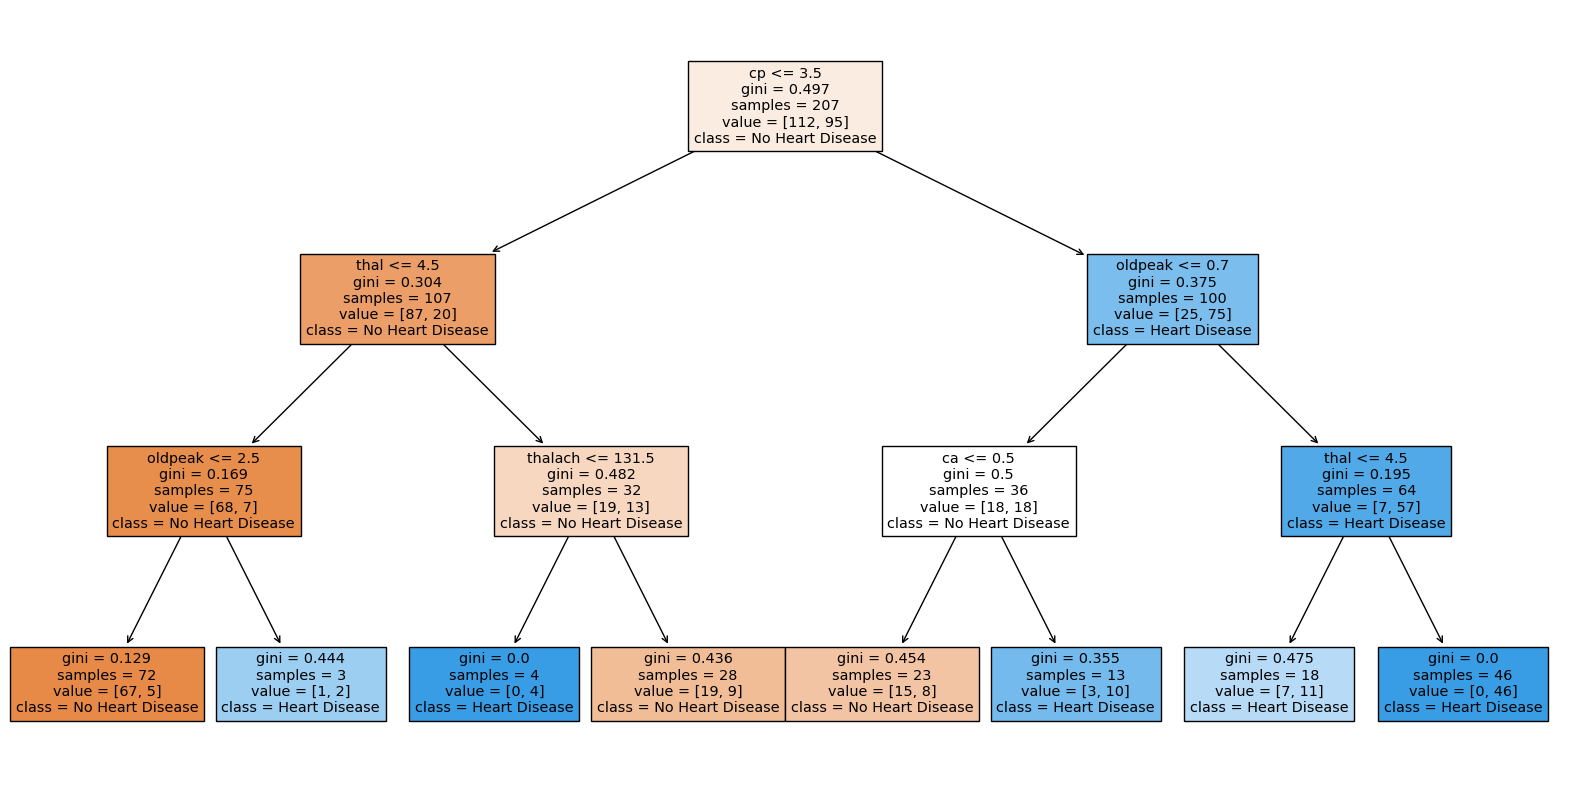

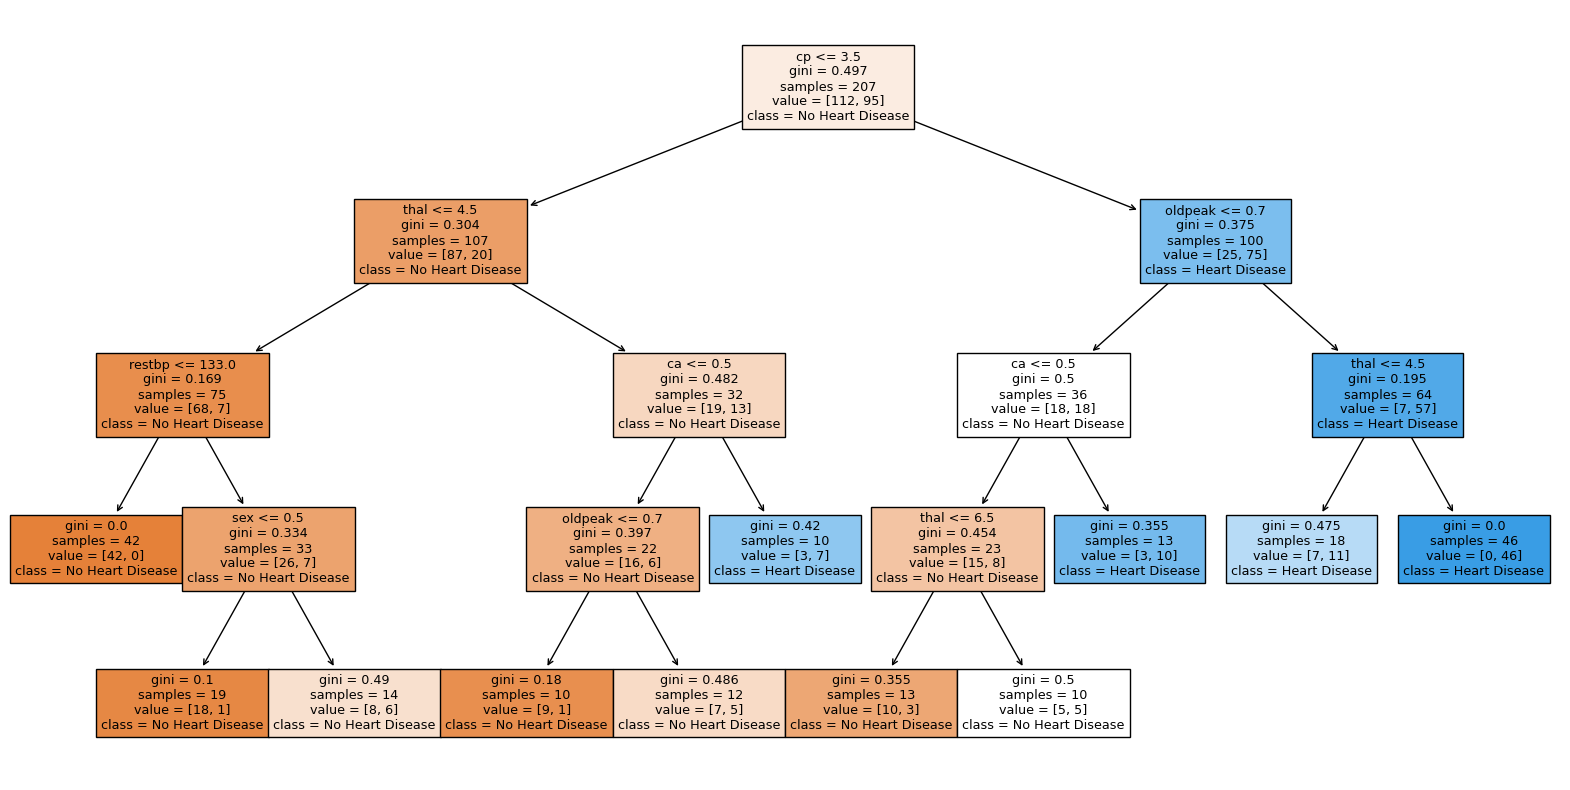

In [ ]:
# Building Decision Tree Model
max_depth_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=0)
max_depth_tree.fit(X_train, y_train)

# Model Evaluation
y_pred_max_depth = max_depth_tree.predict(X_test)

# Visualize feature importances
importances = max_depth_tree.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(12, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.show()

# Decision Tree Visualization
plt.figure(figsize=(20,10))
plot_tree(max_depth_tree, feature_names=list(X_train.columns), class_names=target_names, filled=True)
plt.show()


# Building Decision Tree Model
min_num_tree = DecisionTreeClassifier(criterion='gini', min_samples_leaf=10, random_state=0)
min_num_tree.fit(X_train, y_train)

# Model Evaluation
y_pred_min_num = min_num_tree.predict(X_test)

# Decision Tree Visualization
plt.figure(figsize=(20,10))
plot_tree(min_num_tree, feature_names=list(X_train.columns), class_names=target_names, filled=True)
plt.show()

### 4.2 Illustrating the differences in results


In [ ]:
simple_tree_acc = accuracy_score(y_test, y_pred_gini)
max_depth_tree_acc = accuracy_score(y_test, y_pred_max_depth)
min_num_tree_acc = accuracy_score(y_test, y_pred_min_num)

print(f"Simple Decision Tree: {simple_tree_acc:.2f}")
print(f"Max Depth Tree: {max_depth_tree_acc:.2f}")
print(f"Min Number of samples Tree: {min_num_tree_acc:.2f}")


Simple Decision Tree: 0.74
Max Depth Tree: 0.79
Min Number of samples Tree: 0.83


# **5. Ensemble Methods and Their Comparison**

### 5.1 Training a Random Forest.


In [ ]:
random_forest = RandomForestClassifier(n_estimators=100, random_state=0)
random_forest.fit(X_train, y_train)
random_forest_pred = random_forest.predict(X_test)

### Visualise the tree

* Random Forest models contain many trees (often hundreds), making it impractical to visualize all of them. Typically, you would visualize a few to get a sense of how individual trees are making decisions within the ensemble.

* `random_forest.estimators_` is a list containing all the trees in the forest. You can choose any tree you wish to visualize by changing the index (e.g., rf_clf.estimators_[0] for the first tree).

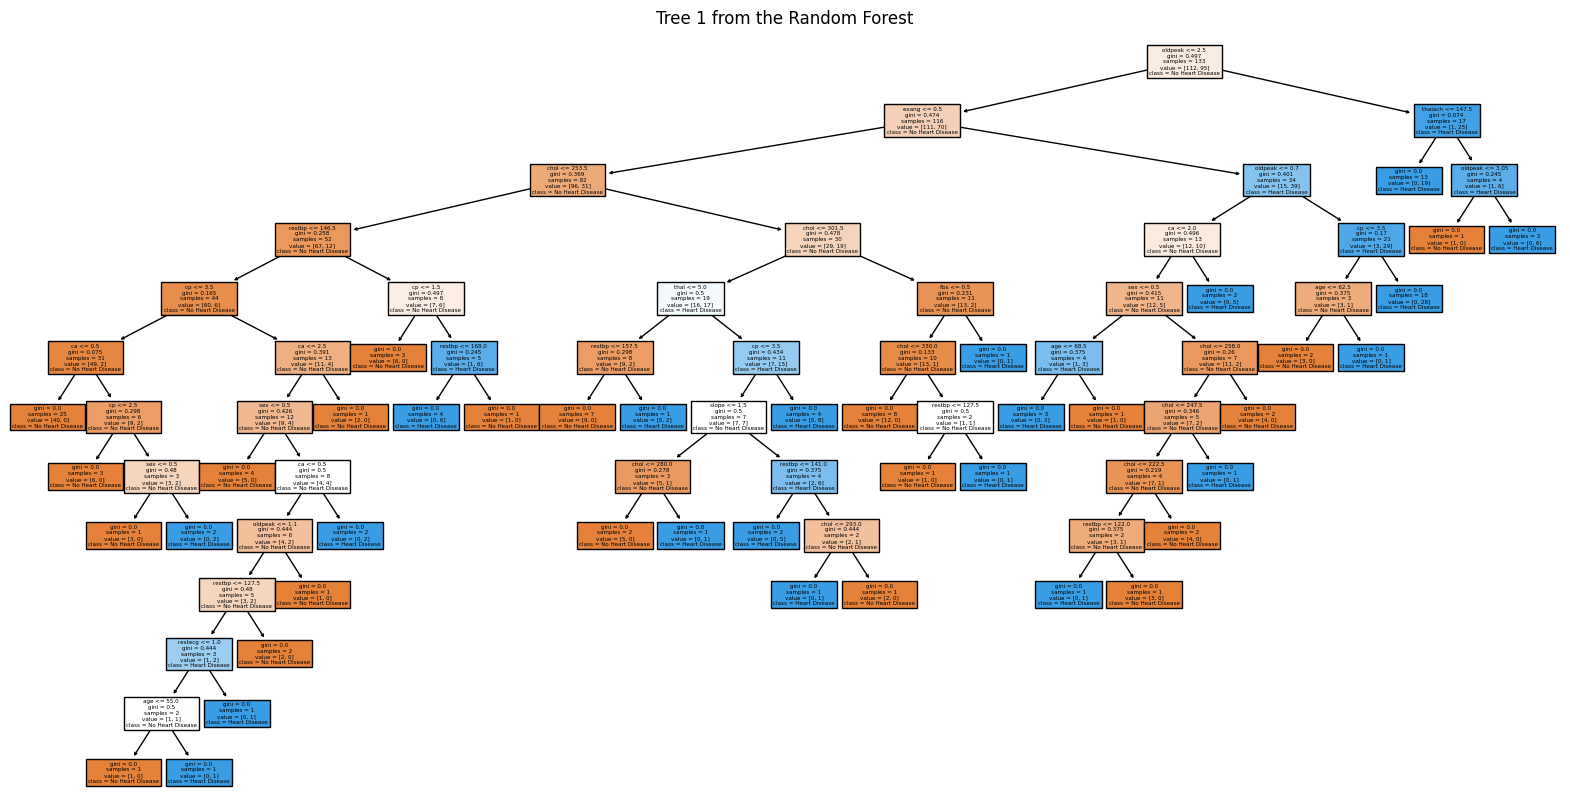

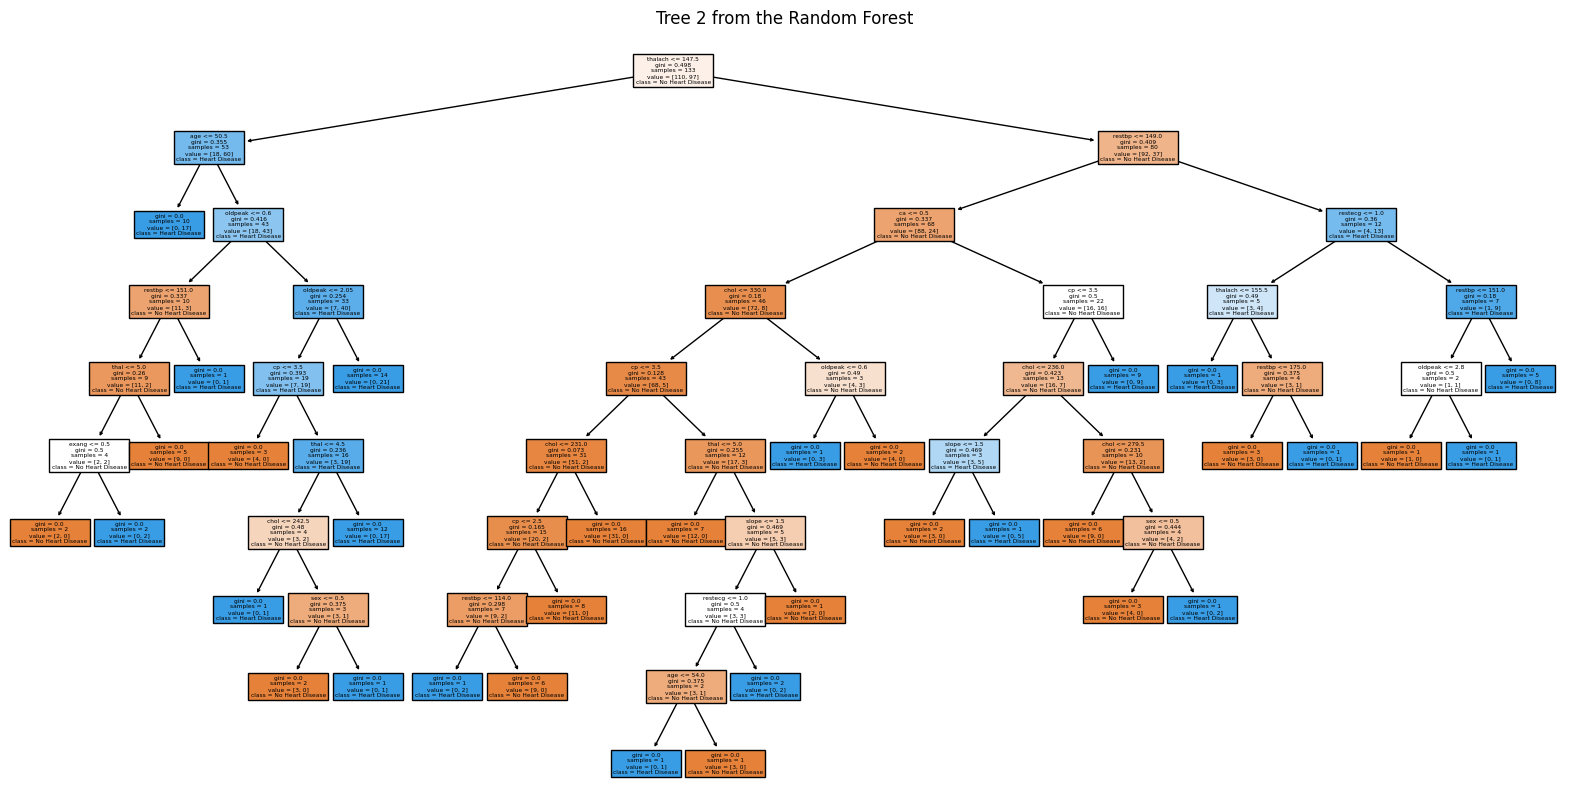

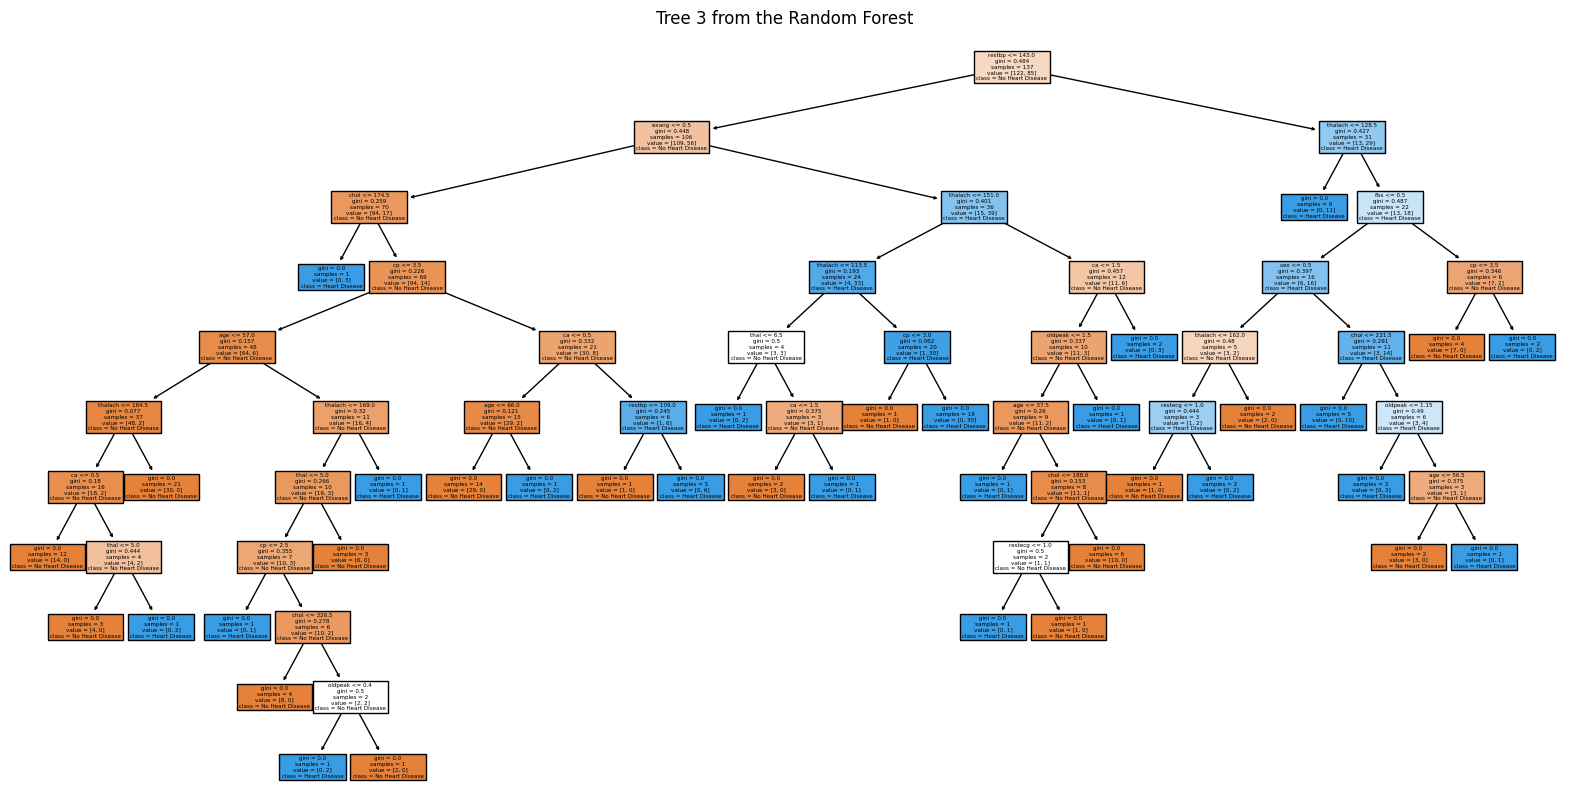

In [ ]:
# Select a single tree from your trained Random Forest model
# Visualize the first three trees
for i in range(3):
    plt.figure(figsize=(20,10))
    tree = random_forest.estimators_[i]
    plot_tree(tree, filled=True, feature_names=list(X_train.columns), class_names=target_names)
    plt.title(f"Tree {i+1} from the Random Forest")
    plt.show()

### 5.2 Choosing a parameter: Creating Random Forest using early stopping criteria

In [ ]:
max_depth_rf = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=0)
max_depth_rf.fit(X_train, y_train)
max_depth_rf_pred = max_depth_rf.predict(X_test)

min_num_rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=0)
min_num_rf.fit(X_train, y_train)
min_num_rf_pred = min_num_rf.predict(X_test)

### 5.3 Comparing performance: Comparing Random Forest against the simple Decision Tree

In [ ]:
random_forest_acc = accuracy_score(y_test, random_forest_pred)
max_depth_rf_acc = accuracy_score(y_test, max_depth_rf_pred)
min_num_rf_acc = accuracy_score(y_test, min_num_rf_pred)


print(f"Simple Decision Tree: {simple_tree_acc:.2f}")
print(f"Random Forest: {random_forest_acc:.2f}", end='\n\n')

print(f"Max Depth Tree: {max_depth_tree_acc:.2f}")
print(f"Max Depth Random Forest: {max_depth_rf_acc:.2f}", end= '\n\n')

print(f"Min Number of samples Tree: {min_num_tree_acc:.2f}")
print(f"Min Number of samples Random Forest: {min_num_rf_acc:.2f}")


Simple Decision Tree: 0.74
Random Forest: 0.78

Max Depth Tree: 0.79
Max Depth Random Forest: 0.81

Min Number of samples Tree: 0.83
Min Number of samples Random Forest: 0.81
